# Modelo de Captaciones - UD Las Palmas 26/27

## Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from math import pi

## Carga de resultados

In [2]:
ruta_data = Path.cwd().parent.parent / 'data' / 'udlaspalmas'

df_plantilla = pd.read_csv(ruta_data / 'df_plantilla_2627.csv')
df_bajas = pd.read_csv(ruta_data / 'df_bajas_2627.csv')
df_impacto = pd.read_csv(ruta_data / 'df_impacto_bajas.csv', index_col=0)
df_estilo = pd.read_csv(ruta_data / 'perfil_estilo_udlp.csv')

print('Carga completada.')
print(f'  Plantilla 26/27: {len(df_plantilla)} jugadores')
print(f'  Bajas confirmadas: {len(df_bajas)}')
print(f'  Métricas con impacto: {len(df_impacto)}')

Carga completada.
  Plantilla 26/27: 22 jugadores
  Bajas confirmadas: 8
  Métricas con impacto: 9


## Necesidades detectadas por posición

In [3]:
# Huecos detectados tras el análisis de bajas y la cobertura actual de la plantilla
NECESIDADES_MERCADO = {
    'Defensa central': {
        'prioridad': 1,
        'num_jugadores': 2,
        'razon': 'Mármol y Barcia suman el 40% de los duelos defensivos del equipo'
    },
    'Mediocentro ofensivo': {
        'prioridad': 2,
        'num_jugadores': 1,
        'razon': 'Benedetti y Viera liberaban 33% de los pases al último tercio'
    },
    'Extremo izquierdo': {
        'prioridad': 3,
        'num_jugadores': 1,
        'razon': 'Solo queda Recoba como extremo izquierdo con ficha'
    }
}

print('Prioridades de mercado para la 26/27:')
for posicion, datos in NECESIDADES_MERCADO.items():
    print(f"\n  [{datos['prioridad']}] {posicion}")
    print(f"      Fichajes necesarios: {datos['num_jugadores']}")
    print(f"      Motivo: {datos['razon']}")

Prioridades de mercado para la 26/27:

  [1] Defensa central
      Fichajes necesarios: 2
      Motivo: Mármol y Barcia suman el 40% de los duelos defensivos del equipo

  [2] Mediocentro ofensivo
      Fichajes necesarios: 1
      Motivo: Benedetti y Viera liberaban 33% de los pases al último tercio

  [3] Extremo izquierdo
      Fichajes necesarios: 1
      Motivo: Solo queda Recoba como extremo izquierdo con ficha


## Perfiles estadísticos

In [4]:
# Los pesos reflejan la importancia de cada métrica para el estilo de Las Palmas
# Se basan en las cargas del PCA del módulo de estilo — no son arbitrarios
PERFILES_OBJETIVO = {
    'Defensa central': {
        'metricas': [
            'Defensive duels per 90',
            'Interceptions per 90',
            'Aerial duels per 90',
            'Passes to final third per 90',
            'Progressive runs per 90'
        ],
        'pesos': [0.30, 0.25, 0.20, 0.15, 0.10],
        'umbrales_minimos': [5.0, 3.5, 5.0, 1.5, 0.5]
    },
    'Mediocentro ofensivo': {
        'metricas': [
            'Passes to final third per 90',
            'Key passes per 90',
            'Progressive runs per 90',
            'Dribbles per 90',
            'xA per 90'
        ],
        'pesos': [0.30, 0.25, 0.20, 0.15, 0.10],
        'umbrales_minimos': [3.0, 1.5, 2.0, 1.0, 0.08]
    },
    'Extremo izquierdo': {
        'metricas': [
            'Progressive runs per 90',
            'Dribbles per 90',
            'Crosses per 90',
            'xA per 90',
            'Passes to final third per 90'
        ],
        'pesos': [0.30, 0.25, 0.20, 0.15, 0.10],
        'umbrales_minimos': [3.5, 2.0, 1.5, 0.10, 2.5]
    }
}

## Función de scoring

In [5]:
def normalizar_metricas(df_candidatos, metricas, df_referencia):
    """
    Normaliza las métricas de candidatos a escala 0-1 respecto al grupo de referencia.
    Usar el grupo de referencia (no los candidatos) evita que un outlier sesgue la escala.
    """
    df_norm = df_candidatos.copy()

    for metrica in metricas:
        minimo = df_referencia[metrica].min()
        maximo = df_referencia[metrica].max()

        rango = maximo - minimo
        if rango == 0:
            df_norm[metrica] = 0.5
        else:
            df_norm[metrica] = (df_candidatos[metrica] - minimo) / rango

    return df_norm


def calcular_score(df_candidatos_norm, metricas, pesos, umbrales, df_original):
    """
    Calcula un score ponderado de 0 a 10 para cada candidato.
    Penaliza a los jugadores que no alcanzan alguno de los umbrales mínimos,
    ya que un central que no duela no encaja en el modelo independientemente del resto.
    """
    df_scores = df_candidatos_norm.copy()

    df_scores['Score_Bruto'] = sum(
        df_scores[m] * p for m, p in zip(metricas, pesos)
    ) * 10

    # Penalización por no alcanzar el umbral mínimo en alguna métrica
    for metrica, umbral in zip(metricas, umbrales):
        no_llega = df_original[metrica] < umbral
        df_scores.loc[no_llega, 'Score_Bruto'] *= 0.80

    df_scores['Score_Final'] = df_scores['Score_Bruto'].clip(0, 10).round(2)
    return df_scores

## Datos de candidatos

In [6]:
# Datos ilustrativos — en producción vienen de Wyscout
candidatos_central = pd.DataFrame({
    'Nombre': ['Candidato A', 'Candidato B', 'Candidato C', 'Candidato D'],
    'Edad': [24, 26, 22, 29],
    'Club_Actual': ['Club 1 (2ªDiv)', 'Club 2 (2ªDiv)', 'Club 3 (1ªDiv)', 'Libre'],
    'Valor_MEur': [3.5, 2.0, 1.5, 0.8],
    'Defensive duels per 90': [7.2, 6.1, 5.8, 8.5],
    'Interceptions per 90': [4.8, 3.9, 3.5, 5.1],
    'Aerial duels per 90': [7.5, 5.2, 4.8, 9.1],
    'Passes to final third per 90': [2.8, 3.5, 2.1, 1.8],
    'Progressive runs per 90': [1.2, 1.8, 0.9, 0.7]
})

candidatos_medio_ofensivo = pd.DataFrame({
    'Nombre': ['Candidato E', 'Candidato F', 'Candidato G'],
    'Edad': [23, 27, 21],
    'Club_Actual': ['Club 4 (2ªDiv)', 'Club 5 (2ªDiv)', 'Club 6 (1ªDiv)'],
    'Valor_MEur': [2.5, 1.8, 4.0],
    'Passes to final third per 90': [4.2, 3.8, 5.1],
    'Key passes per 90': [2.1, 1.9, 2.8],
    'Progressive runs per 90': [3.5, 2.8, 4.1],
    'Dribbles per 90': [2.2, 1.5, 3.0],
    'xA per 90': [0.18, 0.12, 0.25]
})

## Aplicación del modelo: DFC

In [7]:
perfil_dc = PERFILES_OBJETIVO['Defensa central']
metricas_dc = perfil_dc['metricas']

# Usamos los propios candidatos como referencia de normalización
# en produccion seria mejor usar todos los centrales de la competicion como referencia
df_dc_norm = normalizar_metricas(
    candidatos_central[metricas_dc],
    metricas_dc,
    candidatos_central
)

df_dc_scores = calcular_score(
    df_dc_norm,
    metricas_dc,
    perfil_dc['pesos'],
    perfil_dc['umbrales_minimos'],
    candidatos_central
)

ranking_dc = candidatos_central[['Nombre', 'Edad', 'Club_Actual', 'Valor_MEur']].copy()
ranking_dc['Score'] = df_dc_scores['Score_Final']
ranking_dc = ranking_dc.sort_values('Score', ascending=False).reset_index(drop=True)

print('Ranking de candidatos — Defensa central:')
print(ranking_dc.to_string(index=False))

Ranking de candidatos — Defensa central:
     Nombre  Edad    Club_Actual  Valor_MEur  Score
Candidato D    29          Libre         0.8   7.50
Candidato A    24 Club 1 (2ªDiv)         3.5   6.18
Candidato B    26 Club 2 (2ªDiv)         2.0   3.64
Candidato C    22 Club 3 (1ªDiv)         1.5   0.36


## Visualización radar

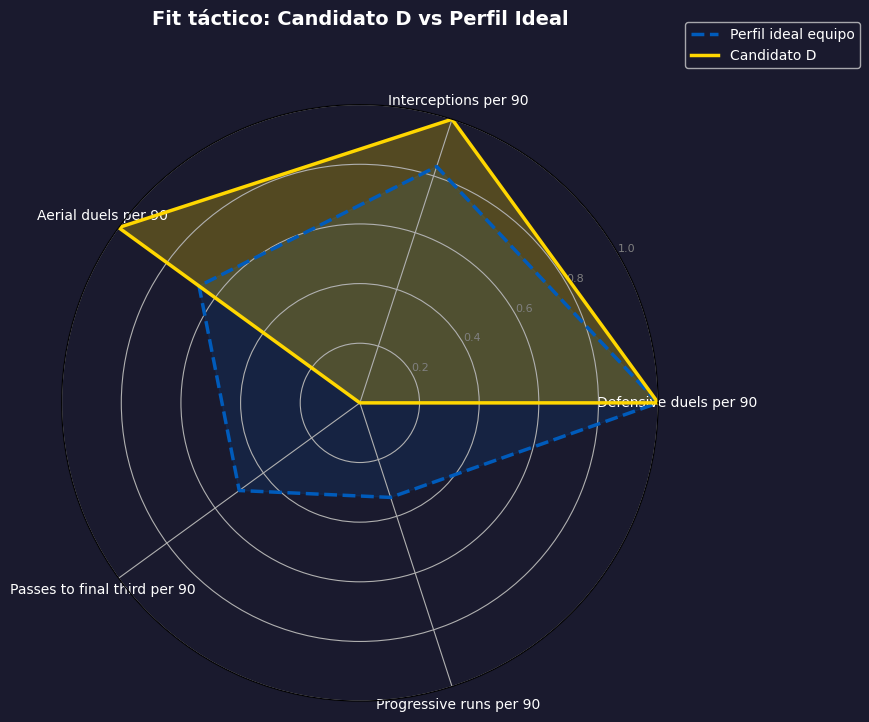

In [8]:
def graficar_radar_candidato_vs_perfil(candidato_serie, perfil_equipo_serie,
                                        metricas, nombre_candidato):
    """
    Radar de doble capa: el candidato en amarillo, el perfil ideal del equipo en azul.
    Facilita ver visualmente dónde encaja bien y dónde puede haber carencias.
    """
    # Normalizar ambos perfiles al mismo rango para que el radar tenga sentido
    n = len(metricas)
    angulos = [i / float(n) * 2 * pi for i in range(n)]
    angulos += angulos[:1]

    vals_candidato = candidato_serie.tolist() + candidato_serie.tolist()[:1]
    vals_perfil = perfil_equipo_serie.tolist() + perfil_equipo_serie.tolist()[:1]

    fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True),
                           facecolor='#1A1A2E')
    ax.set_facecolor('#1A1A2E')
    plt.xticks(angulos[:-1], metricas, color='white', size=10)
    ax.set_rlabel_position(30)
    plt.yticks(color='gray', size=8)
    plt.ylim(0, 1.0)

    ax.plot(angulos, vals_perfil, linewidth=2.5, color='#005BBB',
            linestyle='--', label='Perfil ideal equipo')
    ax.fill(angulos, vals_perfil, color='#005BBB', alpha=0.15)

    ax.plot(angulos, vals_candidato, linewidth=2.5, color='#FFD700',
            label=nombre_candidato)
    ax.fill(angulos, vals_candidato, color='#FFD700', alpha=0.25)

    plt.title(f'Fit táctico: {nombre_candidato} vs Perfil Ideal',
              size=14, color='white', y=1.12, fontweight='bold')
    plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15),
               facecolor='#1A1A2E', labelcolor='white')
    plt.tight_layout()
    plt.show()


# Mejor candidato según el ranking
mejor_candidato = ranking_dc.iloc[0]['Nombre']
fila_candidato = candidatos_central[candidatos_central['Nombre'] == mejor_candidato]

# Normalizar para que el radar sea comparativo
dc_ref = normalizar_metricas(candidatos_central[metricas_dc], metricas_dc, candidatos_central)
vals_mejor = dc_ref.loc[candidatos_central['Nombre'] == mejor_candidato].iloc[0]

# El perfil ideal son los pesos como vector unitario normalizado
perfil_ideal = pd.Series(
    [p / max(perfil_dc['pesos']) for p in perfil_dc['pesos']],
    index=metricas_dc
)

graficar_radar_candidato_vs_perfil(
    vals_mejor, perfil_ideal, metricas_dc, mejor_candidato
)

## Aplicación: Mediocentro ofensivo

In [9]:
perfil_mco = PERFILES_OBJETIVO['Mediocentro ofensivo']
metricas_mco = perfil_mco['metricas']

df_mco_norm = normalizar_metricas(
    candidatos_medio_ofensivo[metricas_mco],
    metricas_mco,
    candidatos_medio_ofensivo
)

df_mco_scores = calcular_score(
    df_mco_norm,
    metricas_mco,
    perfil_mco['pesos'],
    perfil_mco['umbrales_minimos'],
    candidatos_medio_ofensivo
)

ranking_mco = candidatos_medio_ofensivo[['Nombre', 'Edad', 'Club_Actual', 'Valor_MEur']].copy()
ranking_mco['Score'] = df_mco_scores['Score_Final']
ranking_mco = ranking_mco.sort_values('Score', ascending=False).reset_index(drop=True)

print('Ranking de candidatos — Mediocentro ofensivo:')
print(ranking_mco.to_string(index=False))

Ranking de candidatos — Mediocentro ofensivo:
     Nombre  Edad    Club_Actual  Valor_MEur  Score
Candidato G    21 Club 6 (1ªDiv)         4.0  10.00
Candidato E    23 Club 4 (2ªDiv)         2.5   3.72
Candidato F    27 Club 5 (2ªDiv)         1.8   0.00


## Resumen necesidades - Tabla consolidada

In [10]:
def construir_resumen_mercado(necesidades, rankings):
    """Consolida todas las posiciones en una tabla resumen para facilitar la toma de decisiones."""
    filas = []
    for posicion, datos in necesidades.items():
        ranking = rankings.get(posicion)
        if ranking is not None and not ranking.empty:
            mejor = ranking.iloc[0]
            filas.append({
                'Posición': posicion,
                'Prioridad': datos['prioridad'],
                'Fichajes Necesarios': datos['num_jugadores'],
                'Mejor Candidato': mejor['Nombre'],
                'Score': mejor['Score'],
                'Valor (M€)': mejor['Valor_MEur'],
                'Motivo': datos['razon']
            })
        else:
            filas.append({
                'Posición': posicion,
                'Prioridad': datos['prioridad'],
                'Fichajes Necesarios': datos['num_jugadores'],
                'Mejor Candidato': 'Pendiente de análisis',
                'Score': None,
                'Valor (M€)': None,
                'Motivo': datos['razon']
            })

    return pd.DataFrame(filas).sort_values('Prioridad').reset_index(drop=True)


rankings_por_posicion = {
    'Defensa central': ranking_dc,
    'Mediocentro ofensivo': ranking_mco,
    'Extremo izquierdo': pd.DataFrame()
}

df_resumen = construir_resumen_mercado(NECESIDADES_MERCADO, rankings_por_posicion)
print('Resumen de necesidades de mercado — UD Las Palmas 26/27')
print('=' * 65)
print(df_resumen[['Posición', 'Prioridad', 'Fichajes Necesarios', 'Mejor Candidato', 'Score']].to_string(index=False))

Resumen de necesidades de mercado — UD Las Palmas 26/27
            Posición  Prioridad  Fichajes Necesarios       Mejor Candidato  Score
     Defensa central          1                    2           Candidato D    7.5
Mediocentro ofensivo          2                    1           Candidato G   10.0
   Extremo izquierdo          3                    1 Pendiente de análisis    NaN
